<a href="https://colab.research.google.com/github/jtigges20-ai/Bobby_Witt_Plate_Discipline/blob/main/Bobby_Witt_Plate_Discipline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bobby Witt Jr. - 2024 Plate Discipline & Below-Zone Slider Contact
**Baseball analytics portfolio | Python · Statcast · pybaseball**

**Research question:** How do Bobby Witt Jr.’s swing decisions vary by pitch type and location, and how does his whiff rate on sliders below the batter-specific strike zone compare with other right-handed MLB hitters?

This is an **exploratory** study. Re-running downloads may produce different results due to Statcast data updates. Results should not be interpreted as causal or as established player weaknesses/strengths.

## 1. Setup and data collection
Run cells in order. The league-wide download can be slow and memory-intensive. The notebook saves the filtered monthly data locally to avoid repeated downloads.

This project started by examining Bobby Witt Jr.'s plate discipline during the 2024 MLB season, with a focus on identifying potential strengths and weaknesses in his swing decisions. The initial analysis showed that Witt chased changeups at a relatively high rate, while sliders generated the highest whiff rate among the pitch types examined.

In [2]:
%pip -q install pybaseball pandas numpy matplotlib seaborn statsmodels

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Rectangle
from pybaseball import statcast, statcast_batter
from statsmodels.stats.proportion import proportion_confint, proportions_ztest

OUT = Path("figures")
OUT.mkdir(exist_ok=True)
WITT_ID = 677951
DATE_RANGES = [("2024-03-20","2024-03-31"),("2024-04-01","2024-04-30"),
               ("2024-05-01","2024-05-31"),("2024-06-01","2024-06-30"),
               ("2024-07-01","2024-07-31"),("2024-08-01","2024-08-31"),
               ("2024-09-01","2024-09-30")]
SWING_DESCRIPTIONS = {"swinging_strike", "swinging_strike_blocked", "foul", "foul_tip",
    "hit_into_play", "hit_into_play_no_out", "hit_into_play_score", "foul_bunt",
    "missed_bunt", "bunt_foul_tip", "swinging_pitchout"}
WHIFF_DESCRIPTIONS = {"swinging_strike", "swinging_strike_blocked", "foul_tip",
                      "missed_bunt", "bunt_foul_tip"}

def prepare(df):
    df = df.copy()
    df["swing"] = df["description"].isin(SWING_DESCRIPTIONS)
    df["whiff"] = df["description"].isin(WHIFF_DESCRIPTIONS)
    df["in_zone"] = (df["plate_x"].abs() <= 0.83) & df["plate_z"].between(df["sz_bot"], df["sz_top"])
    return df

bobby = statcast_batter("2024-03-28", "2024-09-29", WITT_ID)
bobby = prepare(bobby.dropna(subset=["plate_x", "plate_z", "sz_bot", "sz_top", "description"]))
print("Witt pitches:", len(bobby))

Gathering Player Data
Witt pitches: 2600


## 2. Overall plate discipline
Swing rate = swings / tracked pitches; chase rate = swings / pitches outside an approximate batter-specific zone; whiff rate = misses / swings. The horizontal boundary is fixed at ±0.83 ft; the vertical boundaries use `sz_bot` and `sz_top`.

In [4]:
swings = bobby[bobby["swing"]]
outside = bobby[~bobby["in_zone"]]
metrics = pd.Series({
    "Pitches":len(bobby), "Swings":len(swings),
    "Swing rate (%)":100*bobby["swing"].mean(),
    "Chase rate (%)":100*outside["swing"].mean(),
    "Whiff rate on swings (%)":100*swings["whiff"].mean(),
    "Contact rate on swings (%)":100*(~swings["whiff"]).mean()
})
print(metrics.round(2))

Pitches                       2600.00
Swings                        1330.00
Swing rate (%)                  51.15
Chase rate (%)                  34.24
Whiff rate on swings (%)        22.26
Contact rate on swings (%)      77.74
dtype: float64


## 3. Pitch-location swing-rate heatmap
Bins with fewer than 10 pitches are suppressed. The rectangle is a **fixed illustrative** zone, not the individualized zone used for final below-zone comparisons.

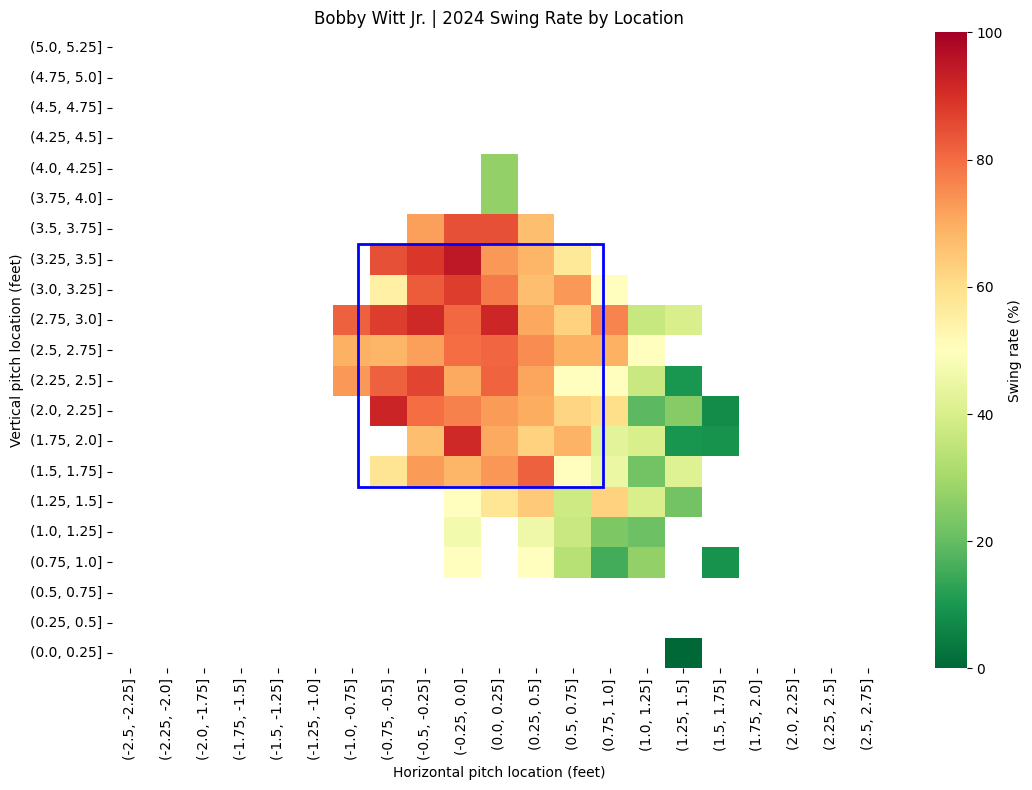

In [5]:
d = bobby.copy()
xedges=np.arange(-2.5,2.76,.25); zedges=np.arange(0,5.26,.25)
d["xb"]=pd.cut(d["plate_x"],xedges); d["zb"]=pd.cut(d["plate_z"],zedges)
g=d.groupby(["zb","xb"],observed=False)["swing"].agg(["mean","count"])
g.loc[g["count"]<10,"mean"]=np.nan
heat=(g["mean"]*100).unstack("xb")
fig,ax=plt.subplots(figsize=(11,8))
sns.heatmap(heat,cmap="RdYlGn_r",vmin=0,vmax=100,ax=ax,cbar_kws={"label":"Swing rate (%)"})
ax.invert_yaxis()
ax.add_patch(Rectangle(((-.83-xedges[0])/.25,(1.5-zedges[0])/.25),1.66/.25,2/.25,fill=False,edgecolor="blue",linewidth=2))
ax.set(title="Bobby Witt Jr. | 2024 Swing Rate by Location",xlabel="Horizontal pitch location (feet)",ylabel="Vertical pitch location (feet)")
fig.tight_layout();fig.savefig(OUT/"swing_rate_heatmap.png",dpi=220);plt.show()

Analysis

The heatmap shows that Witt is most aggressive on pitches located within the strike zone, particularly around the middle and upper portions. His swing rate generally decreases as pitches move farther outside the zone. This suggests that he is relatively selective with his swing decisions, although some locations outside the zone still generate frequent swings.

## 4. Chase rate and whiff rate by pitch type
Only pitch types with at least 30 out-of-zone pitches and 15 out-of-zone swings are plotted. Rates depend on the chosen zone definition.

,pitches,swings,whiffs,chase_rate,whiff_rate
pitch_type,,,,,
CH,140,67,24,47.86,35.82
FS,53,24,9,45.28,37.50
FF,379,136,35,35.88,25.74
SL,322,108,51,33.54,47.22
CU,79,25,11,31.65,44.00
ST,147,44,21,29.93,47.73
FC,126,35,11,27.78,31.43
SI,193,48,8,24.87,16.67


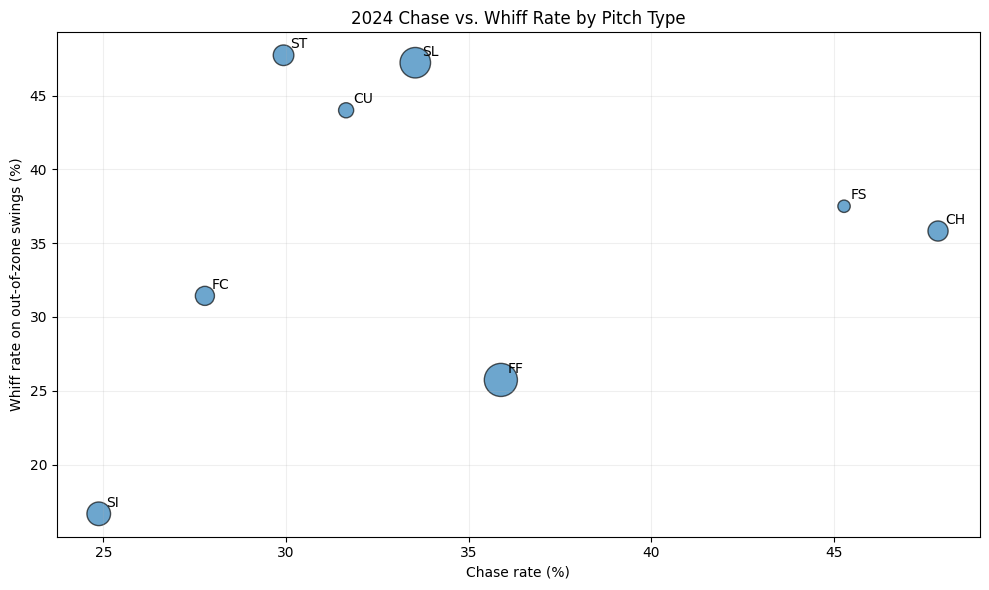

In [6]:
chases=bobby[~bobby["in_zone"]].copy()
summary=chases.groupby("pitch_type")["swing"].agg(pitches="size",swings="sum")
misses=chases[chases["swing"]].groupby("pitch_type")["whiff"].agg(whiffs="sum")
summary=summary.join(misses).fillna({"whiffs":0})
summary["chase_rate"]=100*summary["swings"]/summary["pitches"]
summary["whiff_rate"]=100*summary["whiffs"]/summary["swings"].replace(0,np.nan)
summary=summary[(summary.pitches>=30)&(summary.swings>=15)].sort_values("chase_rate",ascending=False)
display(summary.round(2))
fig,ax=plt.subplots(figsize=(10,6))
ax.scatter(summary.chase_rate,summary.whiff_rate,s=summary.pitches*1.5,alpha=.65,edgecolors="black")
for pitch,r in summary.iterrows():ax.annotate(pitch,(r.chase_rate,r.whiff_rate),xytext=(5,5),textcoords="offset points")
ax.set(xlabel="Chase rate (%)",ylabel="Whiff rate on out-of-zone swings (%)",title="2024 Chase vs. Whiff Rate by Pitch Type")
ax.grid(alpha=.2);fig.tight_layout();fig.savefig(OUT/"chase_vs_whiff.png",dpi=220);plt.show()

Analysis

One of the more interesting findings was the difference between changeups and sliders. Changeups generated the highest chase rate at 45.80%, while sliders produced the highest whiff rate on out-of-zone swings at 53.76%. This suggests that different pitch types may challenge Witt in different ways. Changeups appear effective at getting him to swing outside the zone, while sliders are more effective at generating misses when he does chase.

## 5. Slider locations
This scatterplot shows pitch outcomes; a concentration of whiffs alone does not establish an unusually high whiff **rate**.

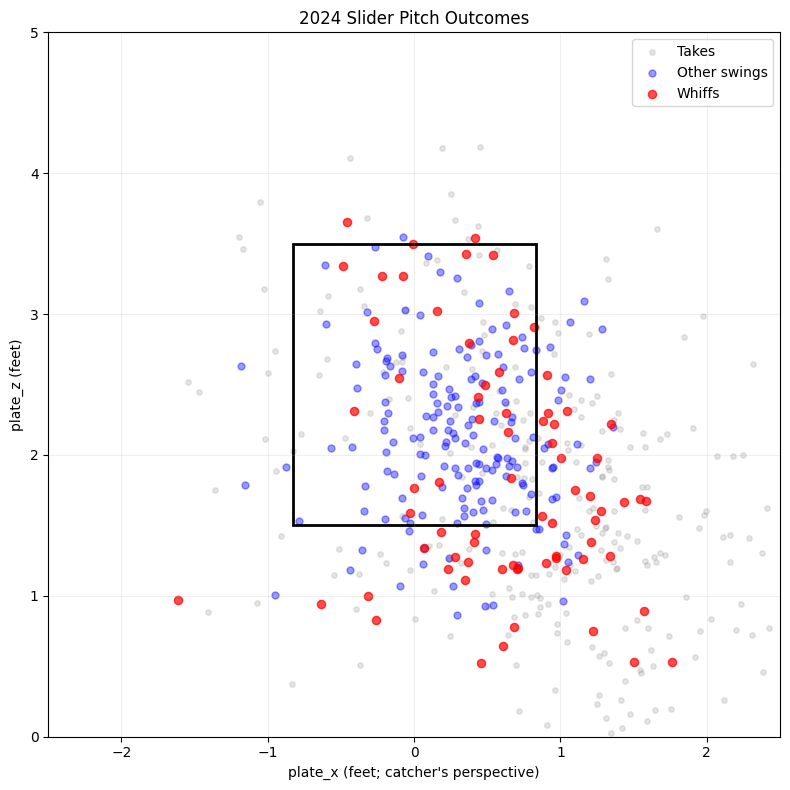

In [7]:
sl=bobby[bobby.pitch_type.eq("SL")].copy()
fig,ax=plt.subplots(figsize=(8,8))
for mask,label,color,size,alpha in [(~sl.swing,"Takes","gray",15,.2),
    (sl.swing & ~sl.whiff,"Other swings","blue",25,.4),(sl.whiff,"Whiffs","red",35,.7)]:
    sub=sl[mask];ax.scatter(sub.plate_x,sub.plate_z,label=label,color=color,s=size,alpha=alpha)
ax.add_patch(Rectangle((-.83,1.5),1.66,2,fill=False,edgecolor="black",linewidth=2))
ax.set(xlim=(-2.5,2.5),ylim=(0,5),xlabel="plate_x (feet; catcher's perspective)",ylabel="plate_z (feet)",title="2024 Slider Pitch Outcomes")
ax.legend();ax.grid(alpha=.2);fig.tight_layout();fig.savefig(OUT/"slider_locations.png",dpi=220);plt.show()

Analysis

After identifying sliders as a pitch type that generated frequent misses, I wanted to investigate where those pitches were being located. The visualization showed several swings and misses on sliders below and outside the strike zone. This initially suggested a potential weakness against low sliders. However, I wanted to compare Witt's performance against other MLB hitters before determining whether this was actually an area of concern.

## 6. MLB comparison dataset
Download March–September 2024 in monthly chunks. Keep `game_date` and `game_pk` for coverage checks. Monthly pitch totals alone cannot prove that every game was retrieved. This is a substantial download; cached files are reused when available.

In [8]:
KEEP=["game_date","game_pk","pitch_type","stand","plate_x","plate_z","sz_bot","sz_top","description","batter"]
cache=Path("statcast_cache");cache.mkdir(exist_ok=True)
parts=[]
for start,end in DATE_RANGES:
    filename=cache/f"statcast_{start}_{end}.csv"
    if filename.exists():
        part=pd.read_csv(filename)
    else:
        raw=statcast(start_dt=start,end_dt=end)
        part=raw[KEEP].copy()
        part.to_csv(filename,index=False)
    print(start,end,"pitches:",len(part),"games:",part.game_pk.nunique(),
          "observed dates:",part.game_date.min(),"to",part.game_date.max())
    parts.append(part)
league=pd.concat(parts,ignore_index=True)
print("Total pitches:",len(league),"unique games:",league.game_pk.nunique())
print("Duplicate pitch rows cannot be checked without pitch-level identifiers; verify coverage against official schedule before claiming completeness.")

This is a large query, it may take a moment to complete


  0%|          | 0/12 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  data_copy[column] = data_copy[column].apply(pd.to_datetime, errors='ignore', format=date_format)
/usr/local/lib/python3.13/dist-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  data_copy[column] = data_copy[column].apply(pd.to_datetime, errors='ignore', format=date_format)
/usr/local/lib/python3.13/dist-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  data_copy[column] = d

2024-03-20 2024-03-31 pitches: 37217 games: 143 observed dates: 2024-03-20 00:00:00 to 2024-03-31 00:00:00
This is a large query, it may take a moment to complete


  0%|          | 0/30 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  data_copy[column] = data_copy[column].apply(pd.to_datetime, errors='ignore', format=date_format)
/usr/local/lib/python3.13/dist-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  data_copy[column] = data_copy[column].apply(pd.to_datetime, errors='ignore', format=date_format)
/usr/local/lib/python3.13/dist-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  data_copy[column] = d

2024-04-01 2024-04-30 pitches: 116769 games: 397 observed dates: 2024-04-01 00:00:00 to 2024-04-30 00:00:00
This is a large query, it may take a moment to complete


  0%|          | 0/31 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  data_copy[column] = data_copy[column].apply(pd.to_datetime, errors='ignore', format=date_format)
/usr/local/lib/python3.13/dist-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  data_copy[column] = data_copy[column].apply(pd.to_datetime, errors='ignore', format=date_format)
/usr/local/lib/python3.13/dist-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  data_copy[column] = d

... (5 outputs left out)

  0%|          | 0/31 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  data_copy[column] = data_copy[column].apply(pd.to_datetime, errors='ignore', format=date_format)
  3%|▎         | 1/31 [00:00<00:12,  2.45it/s]/usr/local/lib/python3.13/dist-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  data_copy[column] = data_copy[column].apply(pd.to_datetime, errors='ignore', format=date_format)
  6%|▋         | 2/31 [00:00<00:12,  2.36it/s]/usr/local/lib/python3.13/dist-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datet

2024-08-01 2024-08-31 pitches: 121441 games: 413 observed dates: 2024-08-01 00:00:00 to 2024-08-31 00:00:00
This is a large query, it may take a moment to complete


  0%|          | 0/30 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  data_copy[column] = data_copy[column].apply(pd.to_datetime, errors='ignore', format=date_format)
/usr/local/lib/python3.13/dist-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  data_copy[column] = data_copy[column].apply(pd.to_datetime, errors='ignore', format=date_format)
/usr/local/lib/python3.13/dist-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  data_copy[column] = d

2024-09-01 2024-09-30 pitches: 113268 games: 385 observed dates: 2024-09-01 00:00:00 to 2024-09-30 00:00:00
Total pitches: 732482 unique games: 2517
Duplicate pitch rows cannot be checked without pitch-level identifiers; verify coverage against official schedule before claiming completeness.


## 7. Below-zone slider whiff-rate comparison
A pitch is below the batter-specific strike zone when `plate_z < sz_bot`. Compare Witt with **other right-handed hitters** (exclude his MLB ID). Both datasets use the same classifications. The numerator counts whiffs; the denominator counts swings, not all pitches.

In [9]:
def below_slider_counts(df):
    valid=df.dropna(subset=["pitch_type","plate_z","sz_bot","description"])
    selected=valid[(valid.pitch_type=="SL") & (valid.plate_z<valid.sz_bot)]
    swings=selected[selected.description.isin(SWING_DESCRIPTIONS)]
    return len(swings),int(swings.description.isin(WHIFF_DESCRIPTIONS).sum())

w_n,w_k=below_slider_counts(bobby)
other=league[(league.stand=="R") & (pd.to_numeric(league.batter,errors="coerce")!=WITT_ID)]
l_n,l_k=below_slider_counts(other)
assert 0<=w_k<=w_n and 0<=l_k<=l_n and w_n>0 and l_n>0
comparison=pd.DataFrame({"Group":["Bobby Witt Jr.","Other right-handed MLB hitters"],"Swings":[w_n,l_n],"Whiffs":[w_k,l_k]})
comparison["Whiff rate (%)"]=100*comparison.Whiffs/comparison.Swings
print(comparison.to_string(index=False))

                         Group  Swings  Whiffs  Whiff rate (%)
                Bobby Witt Jr.      72      37       51.388889
Other right-handed MLB hitters    8608    5609       65.160316


## 8. Statistical uncertainty and visualization
Wilson confidence intervals and the two-proportion z-test assume independent Bernoulli outcomes; baseball pitches are clustered by hitter, pitcher, game, and count. This is an **exploratory** test and does not adjust for multiple comparisons or pitch characteristics.

Observed difference: -13.77 percentage points
Exploratory z=-2.440, p=0.0147
Bobby Witt Jr. 95% Wilson CI: (40.07, 62.57)
Other right-handed MLB hitters 95% Wilson CI: (64.15, 66.16)


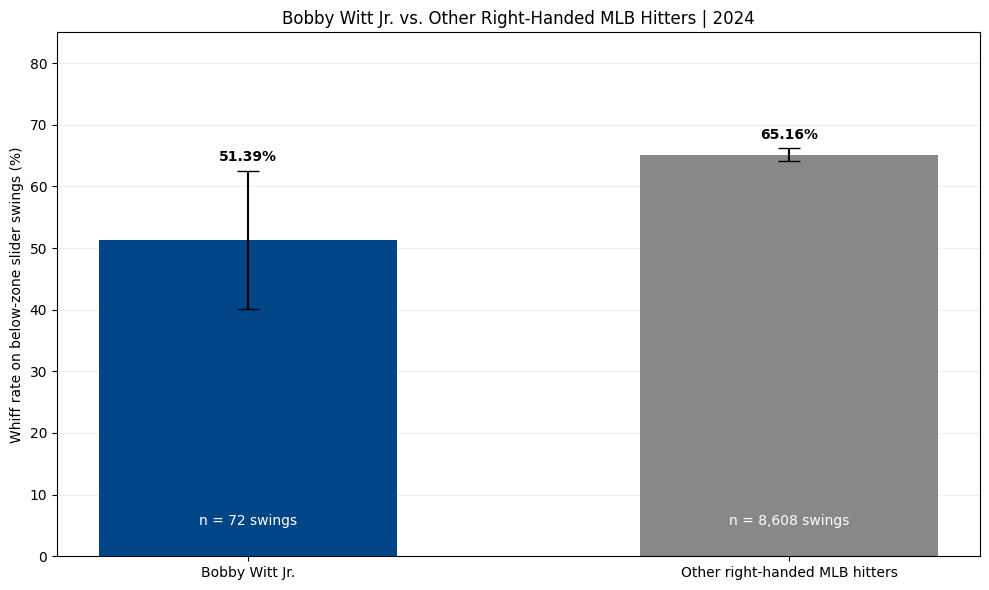

In [10]:
ci=[proportion_confint(int(k),int(n),method="wilson") for n,k in [(w_n,w_k),(l_n,l_k)]]
z,p=proportions_ztest(np.array([w_k,l_k],dtype=float),np.array([w_n,l_n],dtype=float))
print(f"Observed difference: {100*(w_k/w_n-l_k/l_n):.2f} percentage points")
print(f"Exploratory z={z:.3f}, p={p:.4f}")
for label,interval in zip(comparison.Group,ci):print(label,"95% Wilson CI:",tuple(round(x*100,2) for x in interval))
rates=comparison["Whiff rate (%)"].to_numpy()
lo=np.array([x[0]*100 for x in ci]);hi=np.array([x[1]*100 for x in ci])
fig,ax=plt.subplots(figsize=(10,6))
bars=ax.bar(comparison.Group,rates,color=["#004687","#888888"],width=.55,yerr=[rates-lo,hi-rates],capsize=8)
for i,bar in enumerate(bars):
    ax.text(bar.get_x()+bar.get_width()/2,hi[i]+1.5,f"{rates[i]:.2f}%",ha="center",fontweight="bold")
    ax.text(bar.get_x()+bar.get_width()/2,5,f"n = {int(comparison.Swings.iloc[i]):,} swings",ha="center",color="white",fontsize=10)
ax.set_ylim(0,max(85,hi.max()+8));ax.set_ylabel("Whiff rate on below-zone slider swings (%)")
ax.set_title("Bobby Witt Jr. vs. Other Right-Handed MLB Hitters | 2024")
ax.grid(axis="y",alpha=.2);ax.set_axisbelow(True)
fig.tight_layout();fig.savefig(OUT/"witt_slider_whiff_comparison.png",dpi=300,bbox_inches="tight");plt.show()

Analysis

The league comparison produced an interesting result. In my initial analysis, Witt recorded a 51.39% whiff rate against below-zone sliders, compared with 65.16% for other right-handed MLB hitters in the downloaded dataset. The difference was approximately 13.77 percentage points, with a p-value of 0.0147.

Although this was statistically significant under the assumptions of the test, the analysis was exploratory and did not account for differences in pitch quality, count, or repeated observations. Still, the results challenged my initial assumption that below-zone sliders represented a particular weakness for Witt.

## 9. Findings, Limitations, and Next Steps

### Key Findings

This analysis started by examining Bobby Witt Jr.'s plate discipline during the 2024 season, focusing on how his swing decisions and contact rates varied by pitch type and location.

One interesting finding was that changeups generated the highest chase rate, while sliders produced the highest whiff rate on out-of-zone swings. This led me to investigate slider locations more closely, particularly pitches below the strike zone.

Initially, I thought below-zone sliders might represent a weakness in Witt's approach. However, my exploratory comparison showed that Witt recorded a 51.39% whiff rate on these swings, compared with 65.16% for other right-handed MLB hitters. The difference was statistically significant in a preliminary two-proportion z-test (p = 0.0147).

These results suggest that Witt may have better bat-to-ball ability against below-zone sliders than the comparison group, even though these pitches still generate swings and misses.

### Player Development Implications

From a player development perspective, I wouldn't necessarily recommend changing Witt's approach to below-zone sliders based on these findings alone. His lower whiff rate suggests that making contact with these pitches may already be a relative strength.

However, making contact doesn't always mean producing a good outcome. I would want to investigate whether Witt is driving these pitches effectively or primarily producing weak contact and foul balls. If he's frequently making weak contact, improving pitch selection could still be valuable even with a relatively low whiff rate.

### Limitations

These results are exploratory and should be reproduced using the standardized definitions in this notebook before being treated as final findings. The analysis also doesn't account for differences in slider movement, velocity, exact pitch location, count, or pitcher handedness.

Additionally, the statistical test assumes independent swings, even though observations may be correlated. Multiple comparisons were explored before focusing on below-zone sliders, and complete game coverage has not been independently verified.

### Next Steps

Future research could examine contact quality against below-zone sliders using exit velocity, launch angle, and expected batting statistics. I would also compare Witt's performance against hitters with similar profiles and account for pitch characteristics and game situations.

This would help determine whether his lower whiff rate represents a meaningful advantage or whether there are still opportunities to improve his swing decisions.

### Conclusion

The biggest takeaway from this project was that the data challenged my initial assumption. What first appeared to be a potential weakness against low sliders turned into evidence of a possible relative strength when compared with other hitters.

This reinforced the importance of using league benchmarks and statistical testing before drawing conclusions about player performance.

**Data Source:** MLB Statcast via `pybaseball`. Independent educational analysis, not affiliated with MLB or the Kansas City Royals.